# Godunov's method for the double rarefaction problem

We re-use the solver of nb18 without changing a line of it, and feed it a harder Riemann problem: two streams that move apart.

$$\begin{pmatrix}\rho_l\\ u_l\\ p_l\end{pmatrix} = \begin{pmatrix}1.0\\ -2.0\\ 0.4\end{pmatrix} \qquad\qquad \begin{pmatrix}\rho_r\\ u_r\\ p_r\end{pmatrix} = \begin{pmatrix}1.0\\ 2.0\\ 0.4\end{pmatrix}$$

The two states have the same density and the same pressure, and the velocities pull them apart, so the solution is **two rarefactions** travelling outwards with a near-vacuum region between them. There is no shock and no jump in density at the contact.

* **Part I.** Exact solution

* **Part II.** CGF two-shock solver, now used outside its range of validity

* **Part III.** Comparison of 3 reconstructions: `piecewise constant`, `piecewise linear` and `piecewise parabolic`

**References**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Sect. 8.5 and Eq. 8.109. E. F. Toro, *Riemann Solvers and Numerical Methods for Fluid Dynamics*, 2nd ed., Sect. 4.3.3 (Test 2) and Chapter 6.

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

## Part I. Exact solution:

### 1. The double rarefaction problem:

A diaphragm at $x = 0.5$ separating two states that move apart at the same speed.

In [2]:
gamma = 1.4

# Left and right data, q = (rho, u, p)
qL = (1.0, -2.0, 0.4)
qR = (1.0,  2.0, 0.4)

# Diaphragm position and the time at which we compare
x0 = 0.5
tend = 0.15

def sound_speed(rho, p, gamma):
    """
    Speed of sound for an ideal gas
    """
    return np.sqrt(gamma*p/rho)

### 2. The pressure function:

Each outer wave gives one relation between $u_\star$ and $p_\star$. The shock branch comes from the jump conditions, the rarefaction branch from the isentropic Riemann invariant:

$$f_K(p) = \begin{cases} (p - p_K)\left[\dfrac{A_K}{p + B_K}\right]^{1/2} & p > p_K \quad {\rm (shock)} \\[12pt] \dfrac{2c_K}{\gamma - 1}\left[\left(\dfrac{p}{p_K}\right)^{(\gamma - 1)/2\gamma} - 1\right] & p \leq p_K \quad {\rm (rarefaction)} \end{cases} \qquad \begin{aligned} A_K &= \frac{2}{(\gamma + 1)\rho_K}\\ B_K &= \frac{\gamma - 1}{\gamma + 1}p_K \end{aligned}$$

and the star pressure is the root of $f_L + f_R + (u_R - u_L) = 0$.

In [3]:
def f_K(p, rhoK, uK, pK, gamma):
    """
    One side of the pressure function, and its derivative.
    """

    cK = sound_speed(rhoK, pK, gamma)

    AK = 2./((gamma + 1.)*rhoK)
    BK = (gamma - 1.)/(gamma + 1.)*pK

    if p > pK:
        # Shock branch
        f = (p - pK)*np.sqrt(AK/(p + BK))
        df = np.sqrt(AK/(BK + p))*(1. - 0.5*(p - pK)/(BK + p))

    else:
        # Rarefaction branch
        f = 2.*cK/(gamma - 1.)*((p/pK)**((gamma - 1.)/(2.*gamma)) - 1.)
        df = 1./(rhoK*cK)*(p/pK)**(-(gamma + 1.)/(2.*gamma))

    return f, df


def star_state(qL, qR, gamma, tol = 1.e-12):
    """
    Pressure and velocity in the star region, by the Newton-Rhapson method.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    # First guess: the mean of the two pressures
    p = max(tol, 0.5*(pL + pR))

    for it in range(50):

        fL, dfL = f_K(p, rhoL, uL, pL, gamma)
        fR, dfR = f_K(p, rhoR, uR, pR, gamma)

        p_new = max(tol, p - (fL + fR + uR - uL)/(dfL + dfR))

        if abs(p_new - p) < tol*p_new:
            p = p_new
            break

        p = p_new

    fL = f_K(p, rhoL, uL, pL, gamma)[0]
    fR = f_K(p, rhoR, uR, pR, gamma)[0]

    return p, 0.5*(uL + uR) + 0.5*(fR - fL)

In [20]:
# Star state
pstar, ustar = star_state(qL, qR, gamma)

print("p* = %.6f    u* = %.6f" % (pstar, ustar))

# Density on each side of the contact from the isentropic relation
print("rho*L = %.6f  rho*R = %.6f" % (qL[0]*(pstar/qL[2])**(1./gamma), qR[0]*(pstar/qR[2])**(1./gamma)))

# How close are we to a vacuum? The two fans separate when the velocity jump exceeds what the two rarefactions can produce.
cL = sound_speed(qL[0], qL[2], gamma)
cR = sound_speed(qR[0], qR[2], gamma)

print("\n")
print("velocity jump      u_r - u_l = %.4f" % (qR[1] - qL[1]))
print("vacuum threshold  2(c_l + c_r)/(gamma - 1) = %.4f" % (2.*(cL + cR)/(gamma - 1.)))

p* = 0.001894    u* = 0.000000
rho*L = 0.021852  rho*R = 0.021852


velocity jump      u_r - u_l = 4.0000
vacuum threshold  2(c_l + c_r)/(gamma - 1) = 7.4833


### Notes:

Before trusting the Newton iteration, it is worth asking whether there is a root to find. A positive star pressure exists only if $f(0) < 0$, and on the rarefaction branch $f_K(0) = -2c_K/(\gamma - 1)$, so the condition reads:

$$u_r - u_l < \frac{2c_l}{\gamma - 1} + \frac{2c_r}{\gamma - 1}$$

This is Toro's pressure positivity condition (Eq. 4.40). 

If it is violated the two rarefactions pull apart faster than the gas can expand, so a real vacuum opens between them, and the solution has a different structure with no star state at all.

Our data gives $4$ on the left and $7.48$ on the right, so this problem is close to that limit but still on the safe side: the star region survives, with a small but positive pressure and density.

### 3. Sampling the solution:

The solution depends on $x$ and $t$ only through $\xi = (x - x_0)/t$, so one function gives the state anywhere. Here, both outer waves are rarefactions, so the fan branch of `sample` is the one that does all the work, on both sides of the contact.

In [4]:
def sample(xi, qL, qR, pstar, ustar, gamma = 1.4):
    """
    Exact state at xi = (x - x0)/t
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    cL = sound_speed(rhoL, pL, gamma)
    cR = sound_speed(rhoR, pR, gamma)

    if xi <= ustar:

        # Left of the contact
        if pstar > pL:

            # Left shock
            S = uL - cL*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pL + (gamma - 1.)/(2.*gamma))

            if xi < S:
                return rhoL, uL, pL

            ratio = pstar/pL
            rho = rhoL*(ratio + (gamma - 1.)/(gamma + 1.)) /((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Left rarefaction
        c_star = cL*(pstar/pL)**((gamma - 1.)/(2.*gamma))

        if xi < uL - cL:
            return rhoL, uL, pL

        if xi > ustar - c_star:
            return rhoL*(pstar/pL)**(1./gamma), ustar, pstar

        # Inside the fan
        u = 2./(gamma + 1.)*(cL + (gamma - 1.)/2.*uL + xi)
        c = u - xi
        return rhoL*(c/cL)**(2./(gamma - 1.)), u, pL*(c/cL)**(2.*gamma/(gamma - 1.))

    else:

        # Right of the contact
        if pstar > pR:

            # Right shock
            S = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pR + (gamma - 1.)/(2.*gamma))

            if xi > S:
                return rhoR, uR, pR

            ratio = pstar/pR
            rho = rhoR*(ratio + (gamma - 1.)/(gamma + 1.)) /((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Right rarefaction
        c_star = cR*(pstar/pR)**((gamma - 1.)/(2.*gamma))

        if xi > uR + cR:
            return rhoR, uR, pR

        if xi < ustar + c_star:
            return rhoR*(pstar/pR)**(1./gamma), ustar, pstar

        # Inside the fan
        u = 2./(gamma + 1.)*(-cR + (gamma - 1.)/2.*uR + xi)
        c = xi - u
        return rhoR*(c/cR)**(2./(gamma - 1.)), u, pR*(c/cR)**(2.*gamma/(gamma - 1.))


def exact_riemann(x, t, gamma = 1.4):
    """
    The exact solution on a grid of x at time t.
    """

    ps, us = star_state(qL, qR, gamma)

    return np.array([sample((xk - x0)/t, qL, qR, ps, us, gamma) for xk in x]).T

### 4. The exact profiles:

In [5]:
def plot_riemann(runs, t, gamma = 1.4):

    x_fine = np.linspace(0., 1., 1000)
    q = exact_riemann(x_fine, t, gamma)
    e = q[2]/((gamma - 1.)*q[0])

    fig, ax = plt.subplots(4, 1, figsize = (7,12), sharex = True)

    for axis, var, lab in zip(ax, [q[0], q[1], q[2], e], [r"$\rho$", r"$u$", r"$p$", r"$e$"]):
        axis.plot(x_fine, var, color = "black", lw = 1.5, label = "exact")
        axis.set_ylabel(lab)
        axis.grid(alpha = 0.3)

    colours = ["blue", "red", "green"]

    for k, (x, qk, name) in enumerate(runs):

        ek = qk[2]/((gamma - 1.)*qk[0])

        for axis, var in zip(ax, [qk[0], qk[1], qk[2], ek]):
            axis.plot(x, var, "o", color = colours[k % 3], ms = 3., label = name)

    ax[0].legend(loc = "upper right")
    ax[3].set_xlabel(r"$x$")
    plt.xlim(0., 1.)
    plt.tight_layout()
    plt.show()


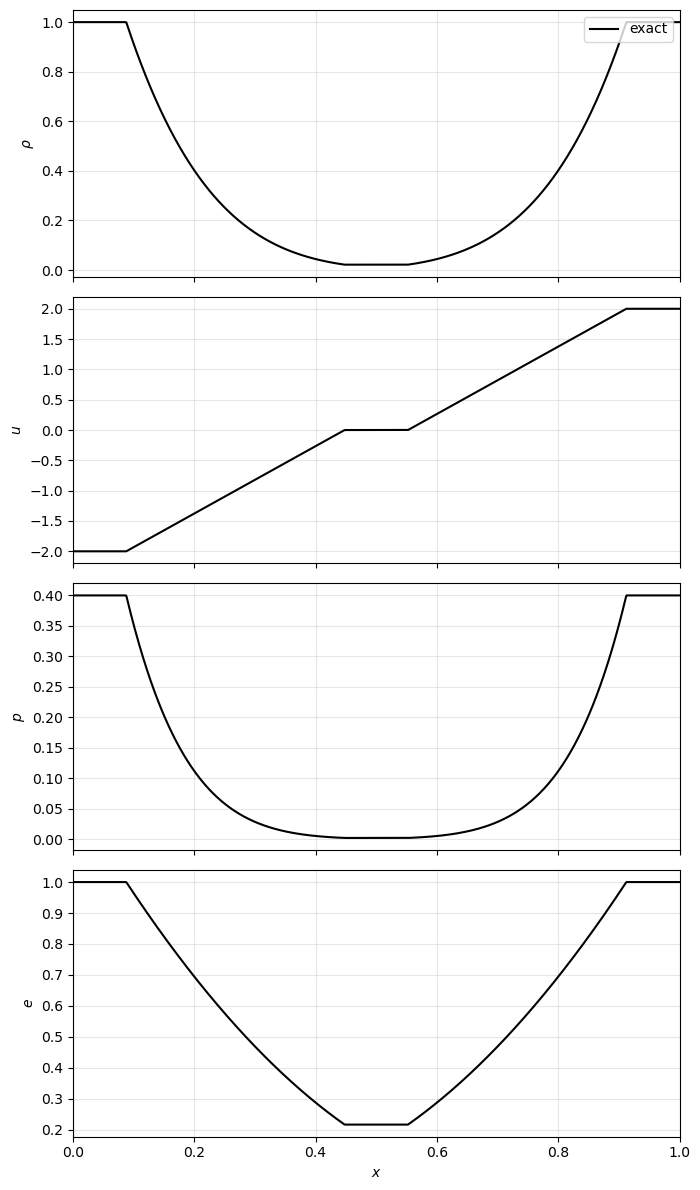

In [6]:
# The exact solution on its own
plot_riemann([], tend)

## Part II. The CGF two-shock solver

The two-shock solver of Colella, Glaz and Ferguson assumes that both outer waves are shocks, so only the shock branch of the pressure function is ever used.

For Sod's problem that assumption was wrong for one wave only, and the error in the star state was about $10^{-4}$. Here it is wrong for **both** waves. Worse than that: with $u_r - u_l = 4$ the equation $f_L + f_R + (u_r - u_l) = 0$ has **no positive root** on the shock branch, because each shock branch is bounded below by $f_K(0) = -1.414$ and the two together cannot produce a velocity jump of $4$. The Newton iteration walks down to the floor of our implementation and stops there.

### 1. The solver:

In [7]:
def two_shock(qL, qR, gamma = 1.4, tol = 1.e-12):
    """
    Star pressure and velocity with both waves taken as shocks.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    def branch(p, rhoK, pK):
        """
        The shock branch of the pressure function, and its derivative.
        """

        AK = 2./((gamma + 1.)*rhoK)
        BK = (gamma - 1.)/(gamma + 1.)*pK

        f = (p - pK)*np.sqrt(AK/(p + BK))
        df = np.sqrt(AK/(BK + p))*(1. - 0.5*(p - pK)/(BK + p))

        return f, df

    p = max(tol, 0.5*(pL + pR))

    for it in range(50):

        fL, dfL = branch(p, rhoL, pL)
        fR, dfR = branch(p, rhoR, pR)

        p_new = max(tol, p - (fL + fR + uR - uL)/(dfL + dfR))

        if abs(p_new - p) < tol*p_new:
            p = p_new
            break

        p = p_new

    fL = branch(p, rhoL, pL)[0]
    fR = branch(p, rhoR, pR)[0]

    return p, 0.5*(uL + uR) + 0.5*(fR - fL)


def riemann_cgf(qL, qR, gamma = 1.4):
    """
    The state on the interface, xi = 0, from the two-shock solver.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    cL = sound_speed(rhoL, pL, gamma)
    cR = sound_speed(rhoR, pR, gamma)

    ps, us = two_shock(qL, qR, gamma)

    # Densities behind each shock
    ratio = (gamma - 1.)/(gamma + 1.)
    rho_sL = rhoL*(ps/pL + ratio)/(ratio*ps/pL + 1.)
    rho_sR = rhoR*(ps/pR + ratio)/(ratio*ps/pR + 1.)

    # Speeds of the two outer waves
    SL = uL - cL*np.sqrt((gamma + 1.)/(2.*gamma)*ps/pL + (gamma - 1.)/(2.*gamma))
    SR = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*ps/pR + (gamma - 1.)/(2.*gamma))

    # Which of the four states sits on the interface?
    if SL >= 0.:
        return rhoL, uL, pL

    if us >= 0.:
        return rho_sL, us, ps

    if SR >= 0.:
        return rho_sR, us, ps

    return rhoR, uR, pR

### 2. How good is the approximation?

We compare again the star state of the two solvers for the double rarefaction.

In [8]:
p_ex, u_ex = star_state(qL, qR, gamma)
p_ts, u_ts = two_shock(qL, qR, gamma)

print("exact      :  p* = %.6f   u* = %.6f" % (p_ex, u_ex))
print("two-shock  :  p* = %.6f   u* = %.6f" % (p_ts, u_ts))
print("difference :       %.2e        %.2e" % (abs(p_ts - p_ex), abs(u_ts - u_ex)))
print()
print("error in p*, relative to p*  : %.1f %%" % (100.*abs(p_ts - p_ex)/p_ex))
print("error in p*, relative to p_l : %.2f %%" % (100.*abs(p_ts - p_ex)/qL[2]))

exact      :  p* = 0.001894   u* = 0.000000
two-shock  :  p* = 0.000000   u* = 0.000000
difference :       1.89e-03        0.00e+00

error in p*, relative to p*  : 100.0 %
error in p*, relative to p_l : 0.47 %


### Note:

- The two-shock solver found no root. It returns the floor of its own iteration, $p_\star = 0$

- Measured against the pressure of the gas, $p_l = p_r = 0.4$, the same error is $0.47\,\%$ (that is the pressure that enters the flux).

- The velocity, which moves mass across the interface, comes out exactly right by symmetry.

## Part III. Finite-volume (FV) solver

### 1. Variables, fluxes and limiters:

The limiters are the ones we used for advection.

In [9]:
def primitive(U, gamma = 1.4):
    """
    From U = (rho, rho*u, E) to q = (rho, u, p).
    """

    rho = U[0]
    u = U[1]/rho
    p = (gamma - 1.)*(U[2] - 0.5*rho*u**2)

    return np.array([rho, u, p])


def conserved(q, gamma = 1.4):
    """
    From q = (rho, u, p) to U = (rho, rho*u, E).
    """

    rho, u, p = q

    return np.array([rho, rho*u, p/(gamma - 1.) + 0.5*rho*u**2])


def flux(q, gamma = 1.4):
    """
    The Euler flux, written in primitive variables.
    """

    rho, u, p = q
    E = p/(gamma - 1.) + 0.5*rho*u**2

    return np.array([rho*u, rho*u**2 + p, u*(E + p)])


def minmod(a, b):
    """
    The smaller slope, zero if the two disagree in sign.
    """

    if a*b <= 0.:
        return 0.

    return a if abs(a) < abs(b) else b


def slope(q, i, limiter = "mc"):
    """
    Limited slope of q in cell i, as an undivided difference.
    """

    dl = q[i] - q[i-1]
    dr = q[i+1] - q[i]
    dc = 0.5*(q[i+1] - q[i-1])

    if limiter == "minmod":
        return minmod(dl, dr)

    return minmod(minmod(2.*dl, 2.*dr), dc)

### 2. Parabolic reconstruction (PPM):

For PPM we interpolate the edge values with the fourth-order formula and then limit them so that the parabola stays monotonic inside the cell.

In [10]:
def ppm_edges(q, ilo, ihi):
    """
    Left and right edge values of the limited parabola in each cell.
    """

    n = len(q)
    qm = q.copy()
    qp = q.copy()

    # Fourth-order interpolant at the interfaces
    qint = np.zeros(n)
    for i in range(ilo - 1, ihi + 3):
        qint[i] = 7./12.*(q[i-1] + q[i]) - 1./12.*(q[i-2] + q[i+1])

    for i in range(ilo - 1, ihi + 2):
        qm[i] = qint[i]
        qp[i] = qint[i+1]

    # Limiting, as in the original PPM paper
    for i in range(ilo - 1, ihi + 2):

        if (qp[i] - q[i])*(q[i] - qm[i]) <= 0.:
            qm[i] = q[i]
            qp[i] = q[i]

        elif (qp[i] - qm[i])*(q[i] - 0.5*(qm[i] + qp[i])) > (qp[i] - qm[i])**2/6.:
            qm[i] = 3.*q[i] - 2.*qp[i]

        elif -(qp[i] - qm[i])**2/6. > (qp[i] - qm[i])*(q[i] - 0.5*(qm[i] + qp[i])):
            qp[i] = 3.*q[i] - 2.*qm[i]

    return qm, qp

### 3. The interface states:

Piecewise constant takes the cell averages themselves. The other two integrate under the reconstruction over the distance each wave travels in $\Delta t$, and keep only the waves moving towards the interface (Zingale, Eqs. 8.34 and 8.48):

$$q^{n+1/2}_{i+1/2,L} = \tilde{q}_+ - \sum_{\nu;\,\lambda^{(\nu)}\geq 0} \mathbf{l}^{(\nu)}\cdot\left[\tilde{q}_+ - \mathcal{I}^{(\nu)}_{+}(q)\right]\mathbf{r}^{(\nu)}$$

In [25]:
def interface_states(q, ilo, ihi, dx, dt, method = "godunov", limiter = "mc", gamma = 1.4):
    """
    Left and right primitive states at every interface.
    """

    n = q.shape[1]

    qL = np.zeros((3, n))
    qR = np.zeros((3, n))

    if method == "godunov":

        # Piecewise constant
        for i in range(ilo, ihi + 2):
            qL[:, i] = q[:, i-1]
            qR[:, i] = q[:, i]

        return qL, qR

    # Edge values of the parabola, only needed by ppm
    if method == "ppm":
        qm = np.zeros((3, n))
        qp = np.zeros((3, n))
        for k in range(3):
            qm[k], qp[k] = ppm_edges(q[k], ilo, ihi)

    for i in range(ilo - 1, ihi + 2):

        rho, u, p = q[:, i]
        c = sound_speed(rho, p, gamma)

        # The three waves
        lam = np.array([u - c, u, u + c])

        # Right eigenvectors, one per column, and left ones, one per row
        r = np.array([[1., 1., 1. ], [-c/rho, 0., c/rho], [c**2, 0., c**2 ]])

        l = np.array([[0., -rho/(2.*c), 1./(2.*c**2)], [1., 0., -1./c**2 ], [0., rho/(2.*c), 1./(2.*c**2)]])

        # Average of the reconstruction seen by each wave, Ip and Im
        Ip = np.zeros((3, 3))
        Im = np.zeros((3, 3))

        for nu in range(3):

            sigma = abs(lam[nu])*dt/dx

            if method == "plm":
                dq = np.array([slope(q[k], i, limiter) for k in range(3)])
                Ip[nu] = q[:, i] + 0.5*(1. - sigma)*dq
                Im[nu] = q[:, i] - 0.5*(1. - sigma)*dq

            else:
                dq = qp[:, i] - qm[:, i]
                q6 = 6.*(q[:, i] - 0.5*(qm[:, i] + qp[:, i]))
                Ip[nu] = qp[:, i] - 0.5*sigma*(dq - q6*(1. - 2./3.*sigma))
                Im[nu] = qm[:, i] + 0.5*sigma*(dq + q6*(1. - 2./3.*sigma))

        # Reference states: the fastest wave moving to each side
        ref_p = Ip[2] if lam[2] > 0. else q[:, i]
        ref_m = Im[0] if lam[0] < 0. else q[:, i]

        left = ref_p.copy()
        right = ref_m.copy()

        for nu in range(3):

            if lam[nu] >= 0.:
                left -= (l[nu] @ (ref_p - Ip[nu]))*r[:, nu]

            if lam[nu] <= 0.:
                right -= (l[nu] @ (ref_m - Im[nu]))*r[:, nu]

        qL[:, i+1] = left
        qR[:, i] = right

    # Floors: Keep density and pressure positive
    qL[0] = np.maximum(qL[0], 1.e-3)
    qL[2] = np.maximum(qL[2], 1.e-3)
    qR[0] = np.maximum(qR[0], 1.e-3)
    qR[2] = np.maximum(qR[2], 1.e-3)

    return qL, qR

### 4. The solver:

Fill the ghost cells, build the interface states, call the Riemann solver at every interface, and do the conservative update.

The timestep comes from the fastest wave on the grid, $\Delta t = C\,\Delta x/\max(|u| + c)$. The only change with respect to nb18 is that the Riemann solver is now an argument, so that we can swap it in Part IV.

In [26]:
def solve_riemann(nx, cfl = 0.8, method = "godunov", limiter = "mc", tend = 0.15, gamma = 1.4, solver = None):
    """
    Finite-volume solution of the Riemann problem on nx cells.
    """

    if solver is None:
        solver = riemann_cgf

    ng = 3
    ilo, ihi = ng, ng + nx - 1

    dx = 1./nx
    x = (np.arange(nx + 2*ng) - ng + 0.5)*dx

    # Initial data
    q = np.zeros((3, nx + 2*ng))
    q[:, x < x0] = np.array(qL)[:, None]
    q[:, x >= x0] = np.array(qR)[:, None]

    U = conserved(q, gamma)

    t = 0.

    while t < tend:

        # Outflow boundaries
        for k in range(ng):
            U[:, ilo - 1 - k] = U[:, ilo]
            U[:, ihi + 1 + k] = U[:, ihi]

        q = primitive(U, gamma)

        # Near a vacuum, E - rho u^2/2 can come out slightly negative,
        # so we floor the cell averages as we already floor the interface states
        q[0] = np.maximum(q[0], 1.e-10)
        q[2] = np.maximum(q[2], 1.e-10)
        U = conserved(q, gamma)

        # Timestep from the fastest wave
        c = sound_speed(q[0], q[2], gamma)
        dt = cfl*dx/np.max(np.abs(q[1]) + c)

        if t + dt > tend:
            dt = tend - t

        # Reconstruct
        qLs, qRs = interface_states(q, ilo, ihi, dx, dt, method, limiter, gamma)

        # Solve the Riemann problem at each interface and build the flux
        F = np.zeros((3, nx + 2*ng))

        for i in range(ilo, ihi + 2):
            F[:, i] = flux(solver(qLs[:, i], qRs[:, i], gamma), gamma)

        # Conservative update
        U[:, ilo:ihi+1] += dt/dx*(F[:, ilo:ihi+1] - F[:, ilo+1:ihi+2])

        t += dt

    return x[ilo:ihi+1], primitive(U, gamma)[:, ilo:ihi+1]

### 5. Comparing the 3 reconstructions:

In [27]:
nx = 1024

x_g, q_g = solve_riemann(nx, method = "godunov", tend = tend)
x_l, q_l = solve_riemann(nx, method = "plm", limiter = "mc", tend = tend)
x_p, q_p = solve_riemann(nx, method = "ppm", tend = tend)

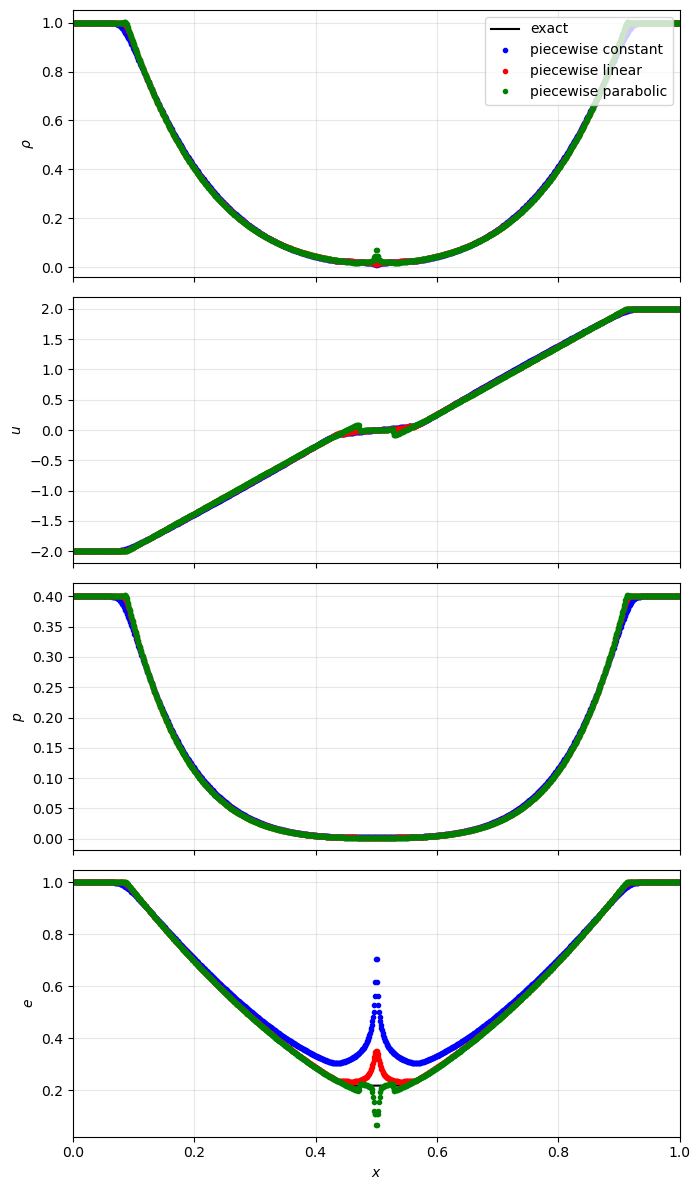

In [28]:
plot_riemann([(x_g, q_g, "piecewise constant"), (x_l, q_l, "piecewise linear"), (x_p, q_p, "piecewise parabolic")], tend)

### Observations:

- The three reconstructions agree on the two fans and on the velocity ramp, and the solution is symmetric, as it must be. 

- The double rarefaction is the standard test for the robustness of a Riemann solver. It actually breaks the two-shock solver as for this data its pressure equation has no positive root at all. The function returnsthe floor of the iteration, $p_\star = 0$.

- Despite that the runs are perfectly reasonable. Why? The initial jump is solved exactly once, at $t = 0$. From the first step onwards the states on either side of an interface differ by very little, so the local Riemann problems are nearly smooth and both solvers agree.

- More accuracy in the reconstruction does not give us a cleaner answer at a near-vacuum. We get a sharper, noisier one.

- The run survives because of the floors we added. The error is concentrated in the internal energy at the centre because both $p$ and $\rho$ small, which is the classic failure mode of Godunov schemes near a vacuum. This is also the reason why production codes carry a dual-energy formulation or a vacuum-aware solver.


$$e=\frac{p}{\rho (\gamma -1)}$$

# Test:

In [35]:
prs = 2.e-20
den = 1.e-21

print(prs/(den*(gamma-1.)))

50.000000000000014
